In [ ]:
# =============================================================================
# Step 1: Library Ingestion and Environment Configuration
# =============================================================================
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Set overall plot aesthetics
sns.set_theme(style="white")

# Load the aggregated cohort dataset
df = pd.read_csv('../data/cohort_retention_rates.csv')

# Convert cohort_month to datetime format and display top records
df['cohort_month'] = pd.to_datetime(df['cohort_month']).dt.strftime('%Y-%m')
#df.head(20)

,cohort_month,cohort_index,active_customers
305,2011-07,1,22
306,2011-07,2,31
307,2011-07,3,28
308,2011-07,4,35
309,2011-07,5,16
310,2011-08,0,106
311,2011-08,1,29
312,2011-08,2,33
313,2011-08,3,28
314,2011-08,4,18


In [2]:
# =============================================================================
# Step 2: Pivot Table Reshaping & Percentage Normalization
# =============================================================================

# Pivot from long to wide format
cohort_pivot = df.pivot(index='cohort_month', columns='cohort_index', values='active_customers')

# Extract Month 0 size (the baseline for each cohort)
cohort_size = cohort_pivot.iloc[:, 0]

# Divide each column by Month 0 and multiply by 100
retention_matrix = cohort_pivot.div(cohort_size, axis=0) * 100

# Inspect the first 5 cohorts across Month 0 to Month 5
retention_matrix.iloc[:5, :6].round(2)

cohort_index,0,1,2,3,4,5
cohort_month,,,,,,
2009-12,100.0,35.29,33.40,42.51,38.01,35.92
2010-01,100.0,20.63,31.07,30.55,26.37,30.03
2010-02,100.0,23.80,22.46,29.14,24.60,20.05
2010-03,100.0,18.96,23.02,24.15,23.25,20.32
2010-04,100.0,19.39,19.39,16.33,18.37,22.45


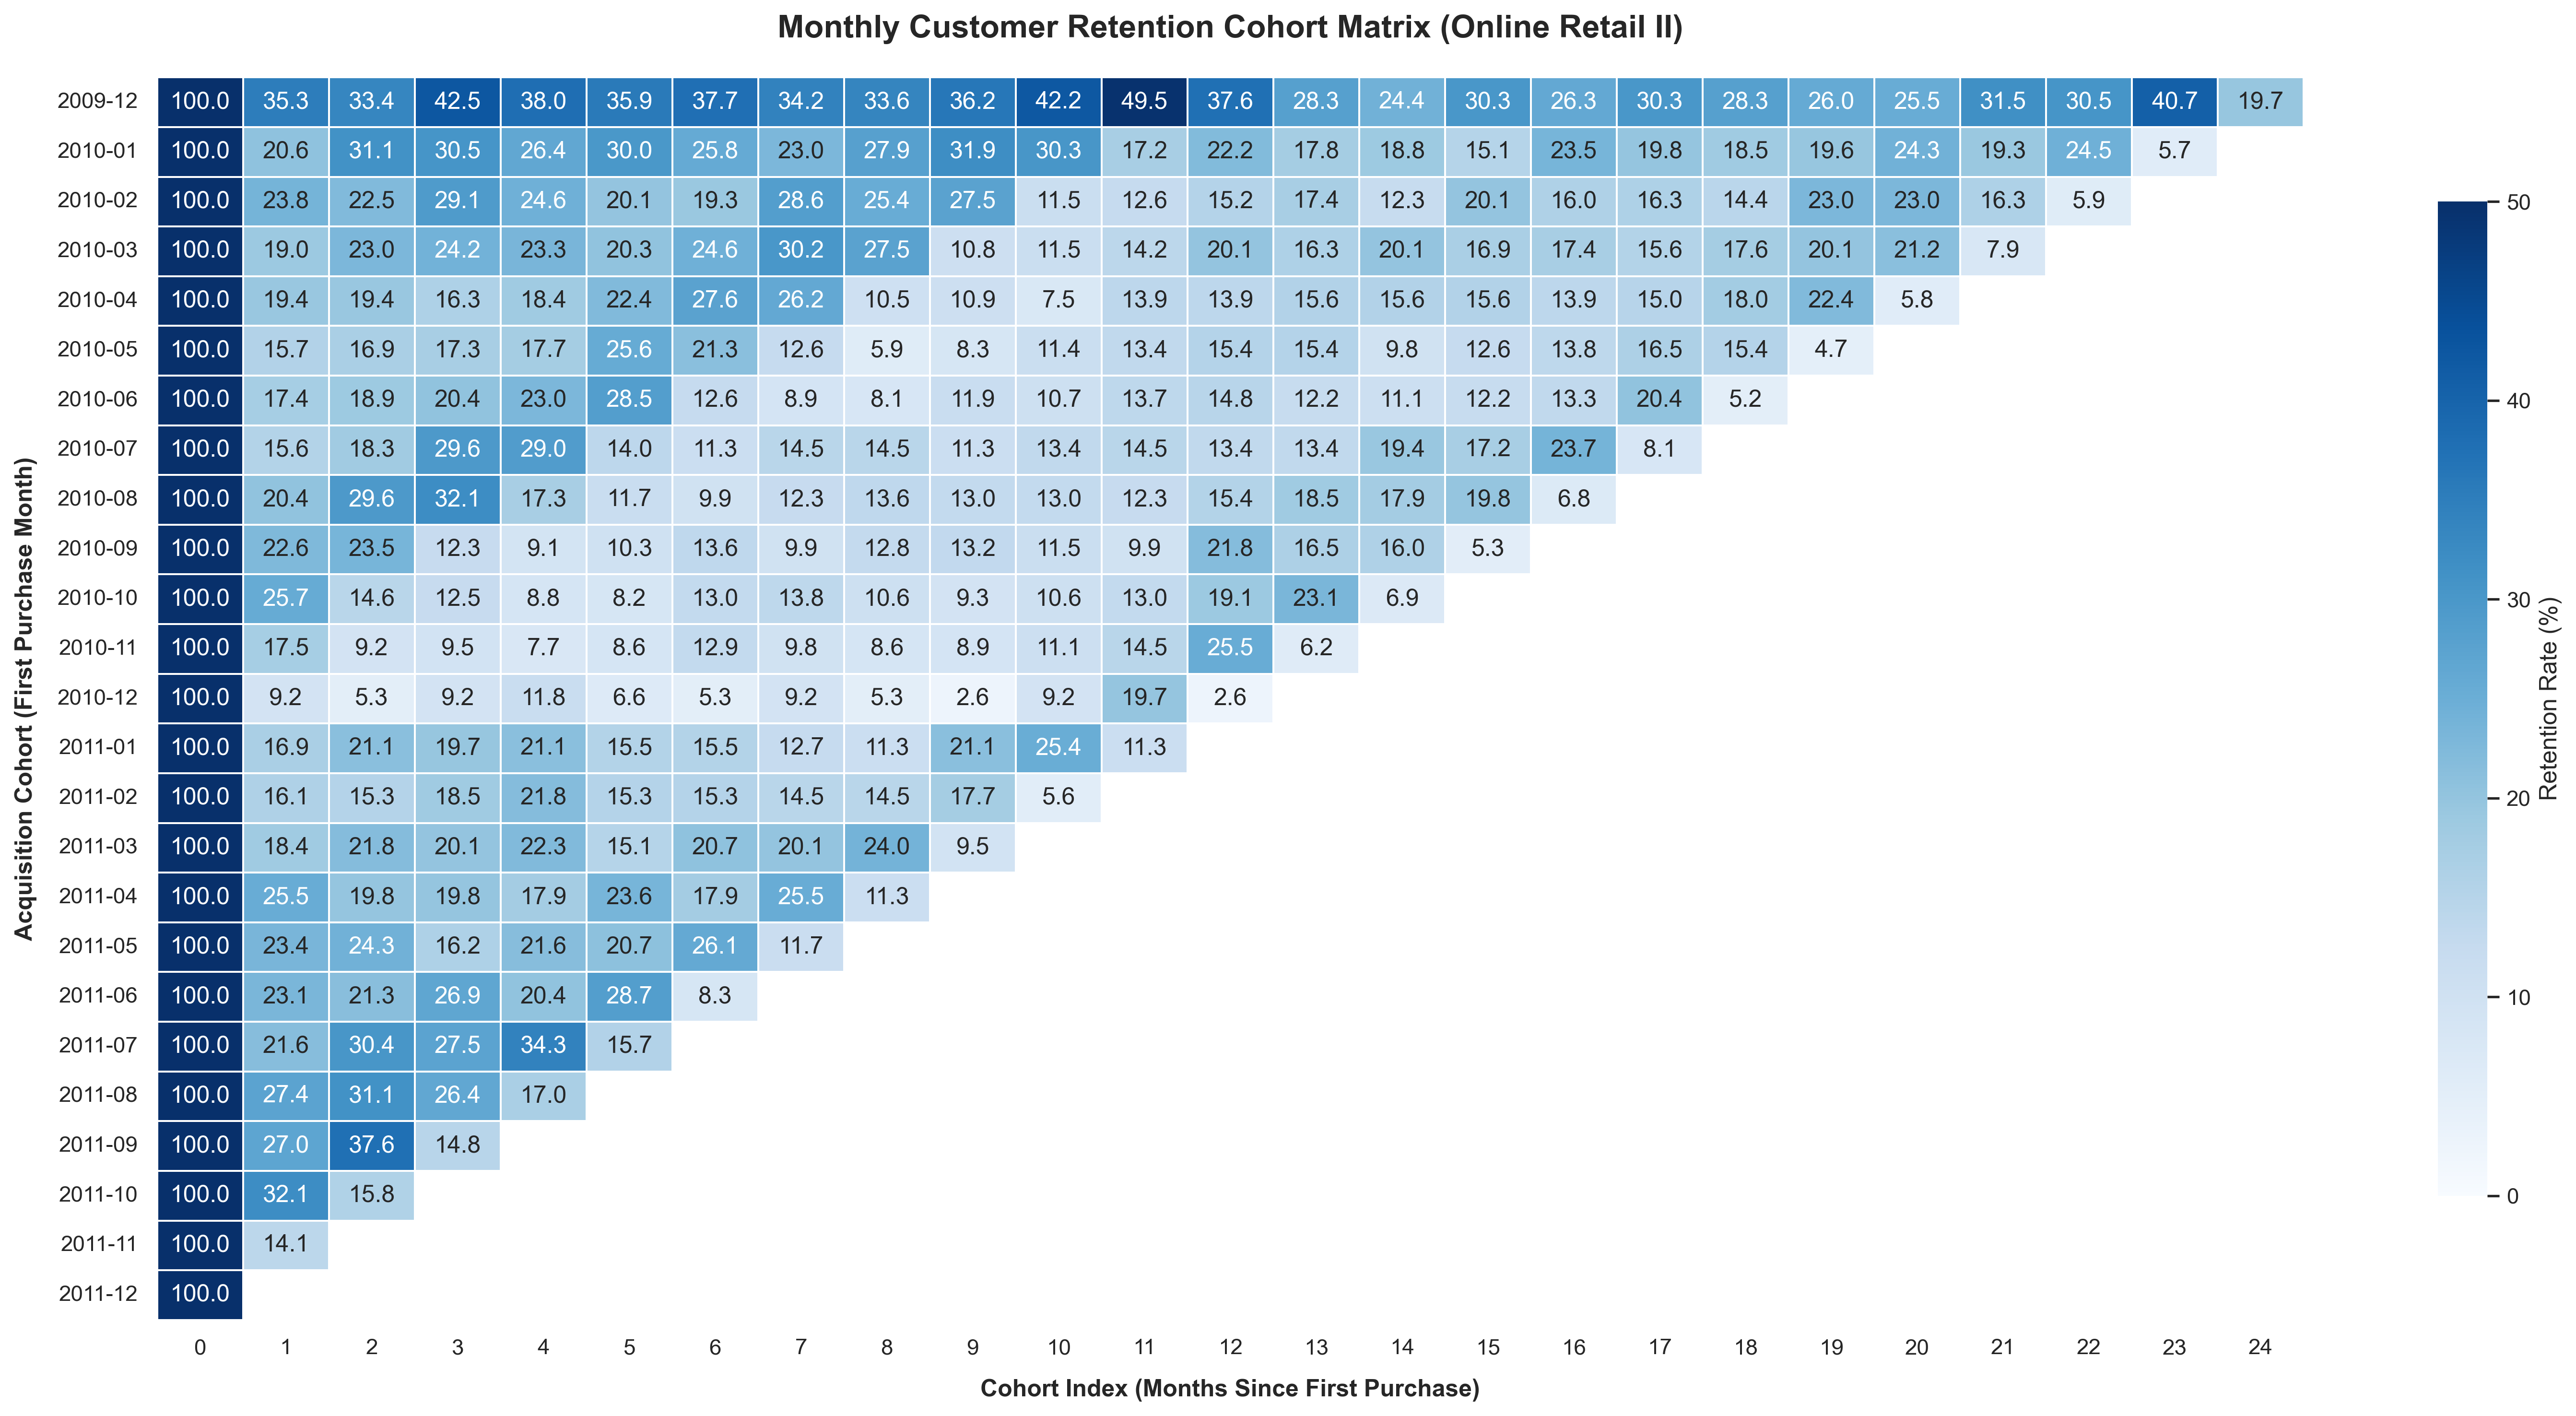

In [7]:
# =============================================================================
# Step 3: Render Publication-Quality Retention Heatmap
# =============================================================================
import numpy as np

# Set up figure dimensions
plt.figure(figsize=(20, 10), dpi=300)

# Create a title and subtitle
plt.title('Monthly Customer Retention Cohort Matrix (Online Retail II)', fontsize=16, fontweight='bold', pad=20)

# Plot the heatmap using a clean blue palette
# We use vmin=0 and vmax=50 to highlight variation in retention across months 1-24
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=0,
    vmax=50,
    cbar_kws={'label': 'Retention Rate (%)', 'shrink': 0.8},
    linewidths=0.5,
    linecolor='white'
)

# Axis labels and typography
plt.xlabel('Cohort Index (Months Since First Purchase)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Acquisition Cohort (First Purchase Month)', fontsize=12, fontweight='bold', labelpad=10)
plt.yticks(rotation=0)

plt.tight_layout()

# Save high-resolution visual for repository documentation
plt.savefig('../images/retention_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()